In [2]:
pip install tensorflow


[notice] A new release of pip is available: 25.0.1 -> 26.2.2
[notice] To update, run: pip3 install --upgrade pip
Note: you may need to restart the kernel to use updated packages.


In [3]:
import os 
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import cv2
from tqdm.auto import tqdm
%matplotlib inline

/Library/Frameworks/Python.framework/Versions/3.13/lib/python3.13/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [4]:
image_paths=[]
image_names=[]
image_dir="DataSet/"
for image_name in tqdm(os.listdir(image_dir)):
    image_path=image_dir + image_name
    image_paths.append(image_path)
    image_names.append(image_name)
    

100%|██████████| 1667/1667 [00:00<00:00, 4088833.20it/s]


In [5]:
len(image_names), len(image_paths)

(1667, 1667)

In [6]:
image_dataframe=pd.DataFrame(index=np.arange(len(image_names)), columns=["image_name","path"])
i=0
for name, path in tqdm(zip(image_names,image_paths)):
    image_dataframe.iloc[i]["image_name"]=name
    image_dataframe.iloc[i]["path"]=path
    i=i+1
    print("Dataframe Shape= ", image_dataframe.shape)

0it [00:00, ?it/s]/var/folders/0f/5vzdhq951l30tm00tc0kgtgm0000gn/T/ipykernel_98341/216892019.py:4: FutureWarning: ChainedAssignmentError: behaviour will change in pandas 3.0!
You are setting values through chained assignment. Currently this works in certain cases, but when using Copy-on-Write (which will become the default behaviour in pandas 3.0) this will never work to update the original DataFrame or Series, because the intermediate object on which we are setting values will behave as a copy.
A typical example is when you are setting values in a column of a DataFrame, like:

df["col"][row_indexer] = value

Use `df.loc[row_indexer, "col"] = values` instead, to perform the assignment in a single step and ensure this keeps updating the original `df`.

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy

  image_dataframe.iloc[i]["image_name"]=name
/var/folders/0f/5vzdhq951l30tm00tc0kgtgm0000gn/T/ipyk

Dataframe Shape=  (1667, 2)
Dataframe Shape=  (1667, 2)
Dataframe Shape=  (1667, 2)
Dataframe Shape=  (1667, 2)
Dataframe Shape=  (1667, 2)
Dataframe Shape=  (1667, 2)
Dataframe Shape=  (1667, 2)
Dataframe Shape=  (1667, 2)
Dataframe Shape=  (1667, 2)
Dataframe Shape=  (1667, 2)
Dataframe Shape=  (1667, 2)
Dataframe Shape=  (1667, 2)
Dataframe Shape=  (1667, 2)
Dataframe Shape=  (1667, 2)
Dataframe Shape=  (1667, 2)
Dataframe Shape=  (1667, 2)
Dataframe Shape=  (1667, 2)
Dataframe Shape=  (1667, 2)
Dataframe Shape=  (1667, 2)
Dataframe Shape=  (1667, 2)
Dataframe Shape=  (1667, 2)
Dataframe Shape=  (1667, 2)
Dataframe Shape=  (1667, 2)
Dataframe Shape=  (1667, 2)
Dataframe Shape=  (1667, 2)
Dataframe Shape=  (1667, 2)
Dataframe Shape=  (1667, 2)
Dataframe Shape=  (1667, 2)
Dataframe Shape=  (1667, 2)
Dataframe Shape=  (1667, 2)
Dataframe Shape=  (1667, 2)
Dataframe Shape=  (1667, 2)
Dataframe Shape=  (1667, 2)
Dataframe Shape=  (1667, 2)
Dataframe Shape=  (1667, 2)
Dataframe Shape=  (1

In [7]:
image_dataframe.head()

,image_name,path
0,064_f261e561.jpg,DataSet/064_f261e561.jpg
1,090_12e1f614.jpg,DataSet/090_12e1f614.jpg
2,002_590bb980.jpg,DataSet/002_590bb980.jpg
3,084_08314073.jpg,DataSet/084_08314073.jpg
4,081_f78b8266.jpg,DataSet/081_f78b8266.jpg


In [8]:
sample_images=[]

In [9]:
def get_images():
    sample_images=[]
    random_image_paths=[np.random.choice(image_dataframe["path"])for i in range(6)]

    plt.figure(figsize=(12,8))
    for i in range(6):
        plt.subplot(2,3,i+1)
        image=cv2.imread(random_image_paths[i])
        image = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)
        sample_images.append(image)
        plt.imshow(image,cmap="gray")
        plt.grid(False)
    plt.tight_layout()
    return sample_images

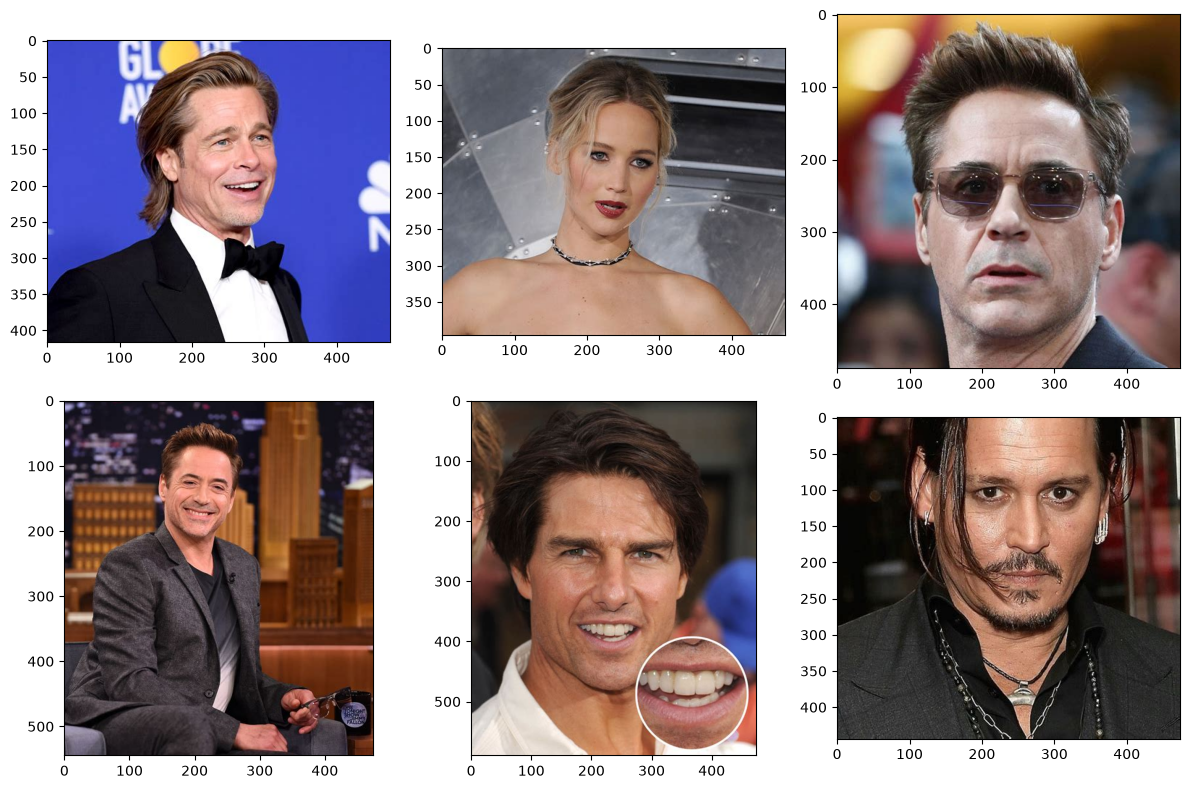

In [10]:
sample_images=get_images()

In [11]:
import requests

url = "https://raw.githubusercontent.com/opencv/opencv/4.x/data/haarcascades/haarcascade_frontalface_default.xml"

response = requests.get(url, timeout=30)

if response.status_code == 200:
    with open("haarcascade_frontalface_default.xml", "wb") as file:
        file.write(response.content)

    print("File downloaded successfully.")

else:
    print("Download failed:", response.status_code)

File downloaded successfully.


In [12]:
%pip list | grep -i opencv

opencv-python      4.10.0.84
Note: you may need to restart the kernel to use updated packages.


In [13]:
%pip uninstall -y opencv-python

Found existing installation: opencv-python 4.10.0.84
Uninstalling opencv-python-4.10.0.84:
  Successfully uninstalled opencv-python-4.10.0.84
Note: you may need to restart the kernel to use updated packages.


In [14]:
%pip install opencv-python==4.10.0.84

  Using cached opencv_python-4.10.0.84-cp37-abi3-macosx_11_0_arm64.whl.metadata (20 kB)
Using cached opencv_python-4.10.0.84-cp37-abi3-macosx_11_0_arm64.whl (54.8 MB)

[notice] A new release of pip is available: 25.0.1 -> 26.2.2
[notice] To update, run: pip3 install --upgrade pip
Note: you may need to restart the kernel to use updated packages.


In [15]:
import cv2

print("OpenCV version:", cv2.__version__)
print("OpenCV location:", cv2.__file__)
print("CascadeClassifier available:", hasattr(cv2, "CascadeClassifier"))
print("OpenCV module:", cv2)

OpenCV version: 4.10.0
OpenCV location: /Library/Frameworks/Python.framework/Versions/3.13/lib/python3.13/site-packages/cv2/__init__.py
CascadeClassifier available: True
OpenCV module: <module 'cv2' from '/Library/Frameworks/Python.framework/Versions/3.13/lib/python3.13/site-packages/cv2/__init__.py'>


In [16]:
def haar_cascade_detection(sample_images):
    face_cascade=cv2.CascadeClassifier("haarcascade_frontalface_default.xml")
    for image in tqdm(sample_images):
        gray=cv2.cvtColor(image,cv2.COLOR_RGB2GRAY)
        faces = face_cascade.detectMultiScale(
        gray,
        scaleFactor=1.05,
        minNeighbors=5,
        minSize=(50, 50)
)

        for(x_coordinate, y_coordinate, width, height) in faces:
            cv2.rectangle(image,(x_coordinate,y_coordinate),(x_coordinate + width, y_coordinate + height),(100,0,0),2)

In [17]:
haar_cascade_detection(sample_images)

100%|██████████| 6/6 [00:00<00:00, 32.04it/s]


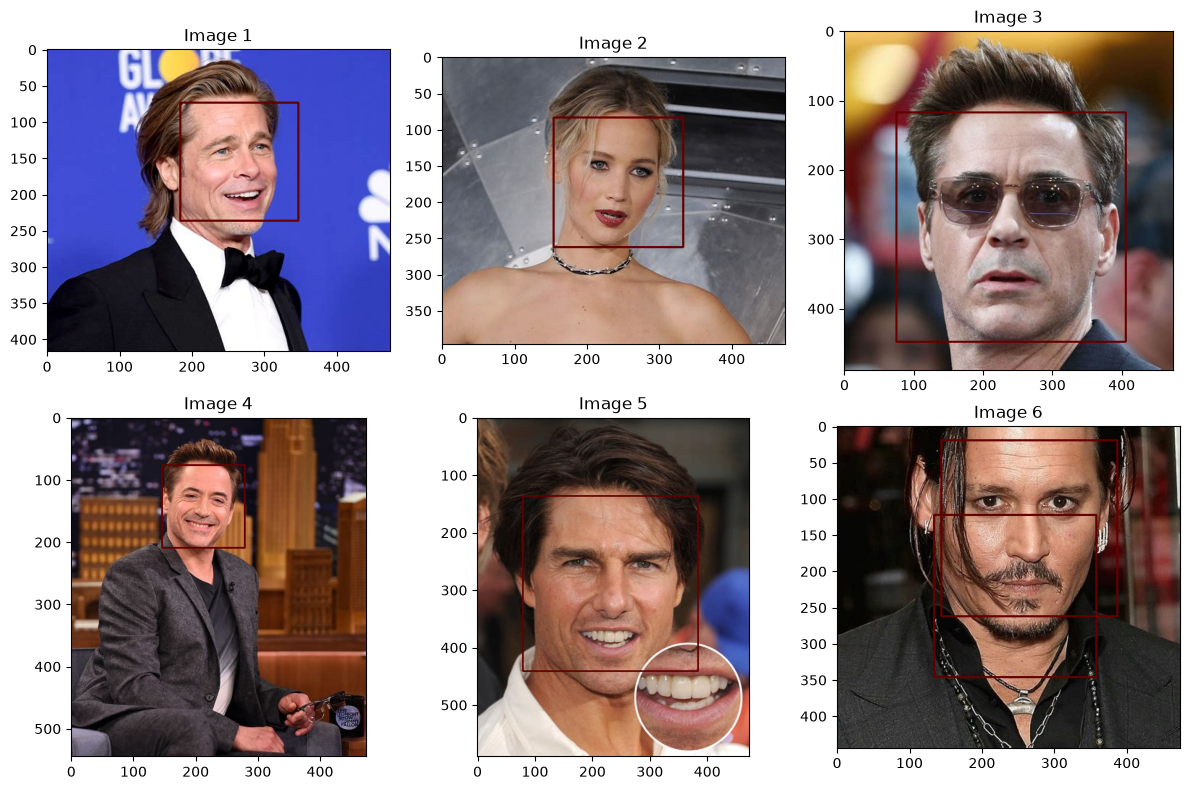

In [18]:
plt.figure(figsize=(12,8))
for i in range(6):
    plt.subplot(2,3, i+1)
    plt.imshow(sample_images[i],cmap='gray')
    plt.title("Image {}".format(i+1))
    plt.grid(False)
plt.tight_layout()

# Trying on more image

In [19]:
def load_image():
    image1=cv2.imread("DataSet/001_5ef3e95c.jpg")
    image1=cv2.cvtColor(image1,cv2.COLOR_BGR2RGB)

    image2=cv2.imread("DataSet/001_9adc92c2.jpg")
    image2=cv2.cvtColor(image2,cv2.COLOR_BGR2RGB)

    plt.figure(figsize = (12, 8))
    plt.subplot(1,2,1) 
    plt.title("The One During A Conference", fontsize = 13)
    plt.imshow(image1, cmap = "gray")
    plt.grid(False)

    plt.subplot(1,2,2) 
    plt.title("The One With Home Buddies!", fontsize = 13)
    plt.imshow(image2, cmap = "gray")
    plt.grid(False)

    plt.tight_layout()
    return image1, image2

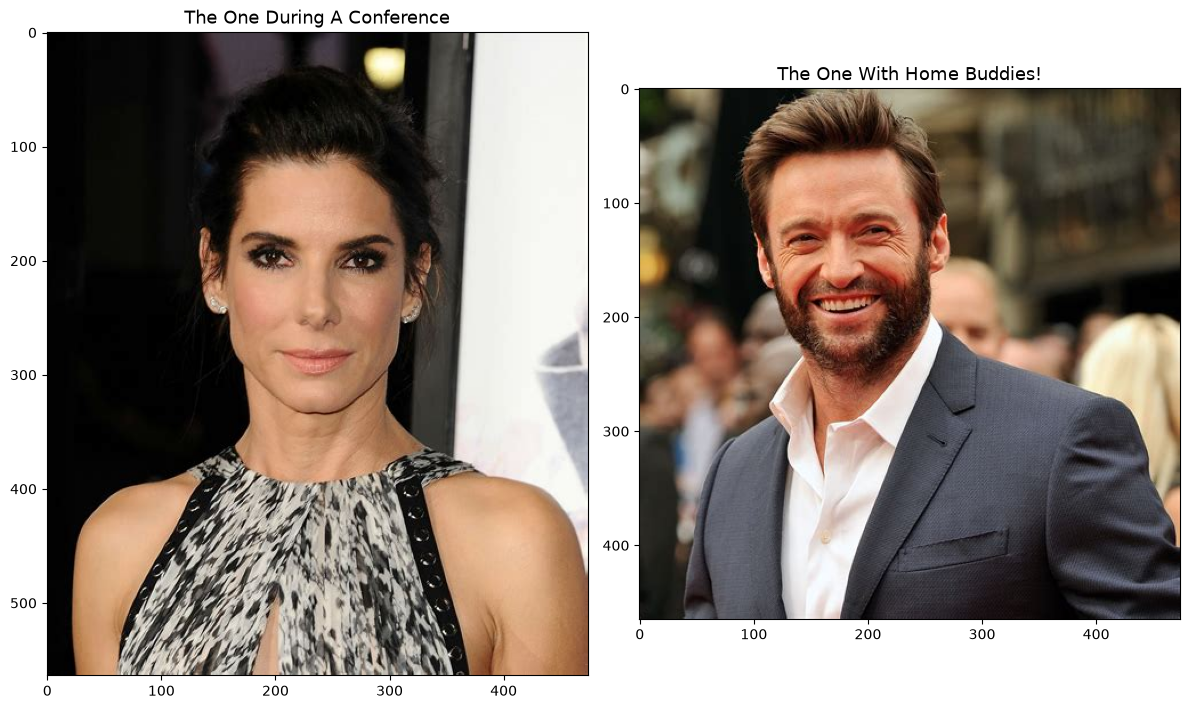

In [20]:
image1, image2= load_image()

In [21]:
haar_cascade_detection([image1,image2])

100%|██████████| 2/2 [00:00<00:00, 49.62it/s]


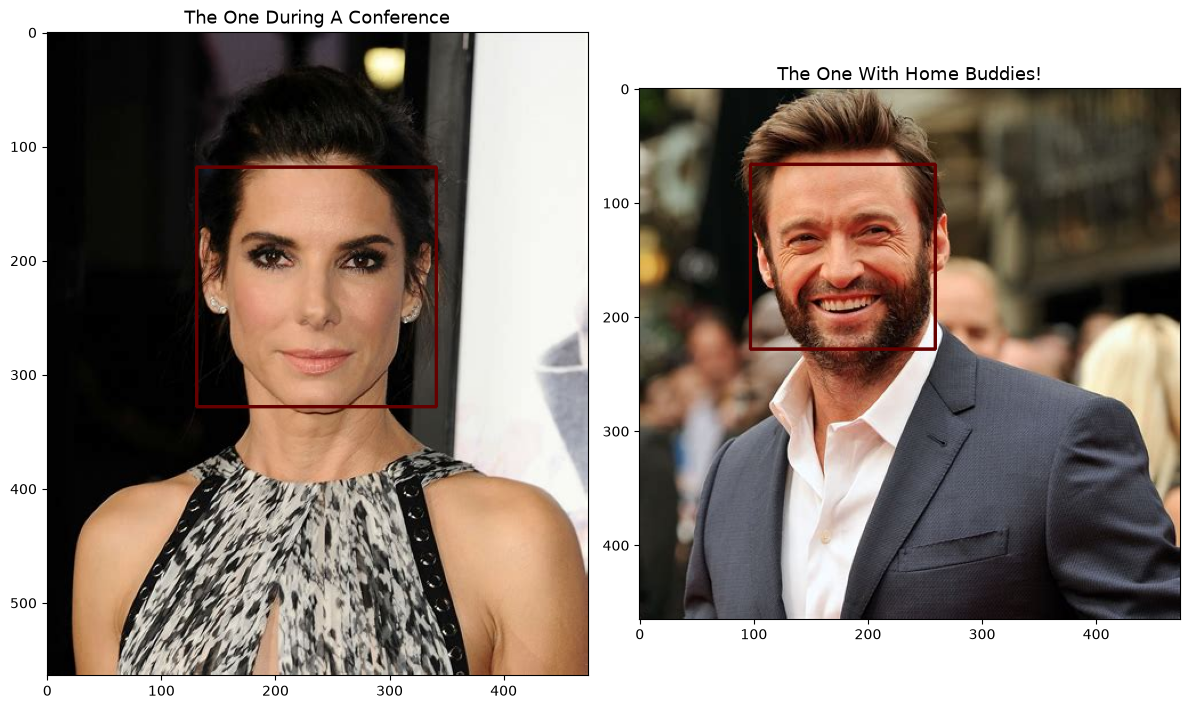

In [22]:
plt.figure(figsize=(12,8))
plt.subplot(1,2,1)
plt.title("The One During A Conference", fontsize = 13)
plt.imshow(image1, cmap = "gray")
plt.grid(False)

plt.subplot(1,2,2) 
plt.title("The One With Home Buddies!", fontsize = 13)
plt.imshow(image2, cmap = "gray")
plt.grid(False)

plt.tight_layout()

# Multi-task Cascaded Convolutional Networks

In [23]:
pip install mtcnn


[notice] A new release of pip is available: 25.0.1 -> 26.2.2
[notice] To update, run: pip3 install --upgrade pip
Note: you may need to restart the kernel to use updated packages.


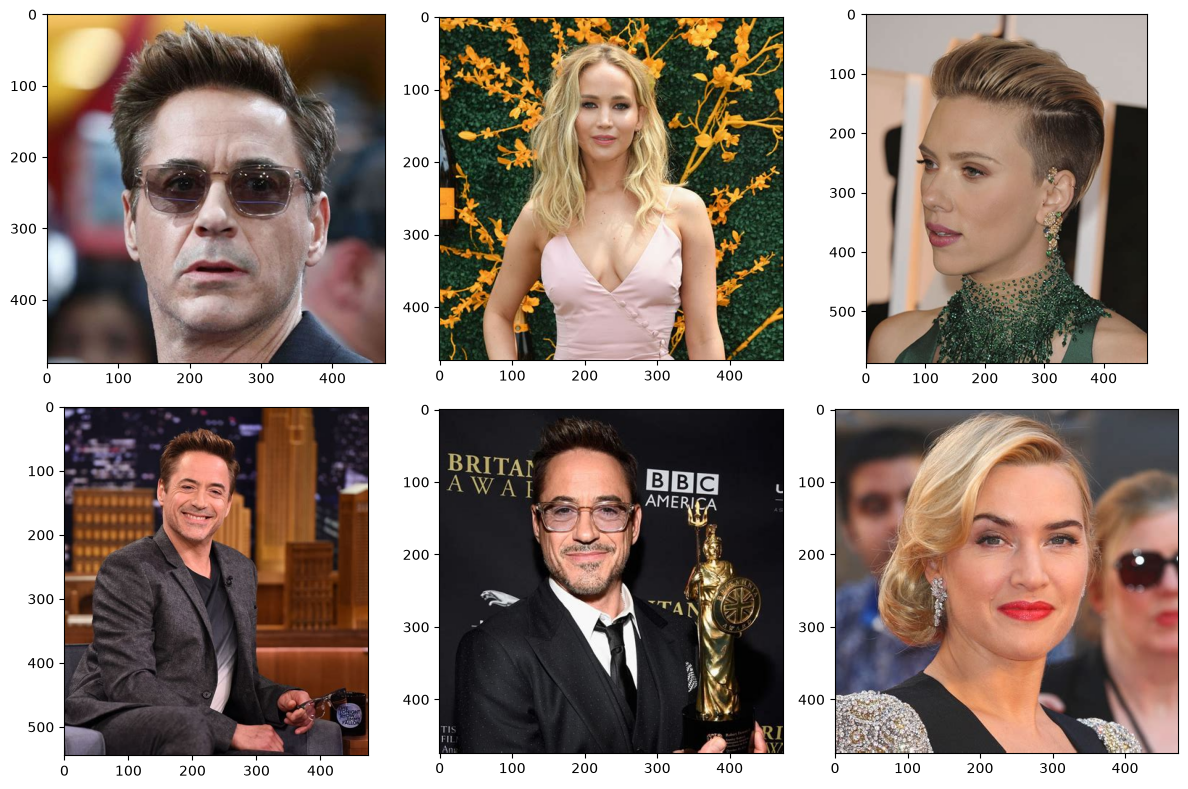

In [24]:
sample_images=get_images()

In [26]:
from mtcnn.mtcnn import MTCNN

In [27]:
detector=MTCNN()

Exception ignored in: <_io.BufferedReader>
Traceback (most recent call last):
  File "/Library/Frameworks/Python.framework/Versions/3.13/lib/python3.13/site-packages/lz4/frame/__init__.py", line 753, in flush
    self._fp.flush()
ValueError: I/O operation on closed file.
Exception ignored in: <_io.BufferedReader>
Traceback (most recent call last):
  File "/Library/Frameworks/Python.framework/Versions/3.13/lib/python3.13/site-packages/lz4/frame/__init__.py", line 753, in flush
    self._fp.flush()
ValueError: I/O operation on closed file.
Exception ignored in: <_io.BufferedReader>
Traceback (most recent call last):
  File "/Library/Frameworks/Python.framework/Versions/3.13/lib/python3.13/site-packages/lz4/frame/__init__.py", line 753, in flush
    self._fp.flush()
ValueError: I/O operation on closed file.


In [30]:
def mtcnn_detector(sample_images) :
    for image in tqdm(sample_images):
        face_location=detector.detect_faces(image)
        for face in face_location:
            x_coordinate, y_coordinate, width, height= face['box']

            cv2.rectangle(image,(x_coordinate, y_coordinate), (x_coordinate + width, y_coordinate + height),(0,0,100),2)

In [31]:
mtcnn_detector(sample_images)

100%|██████████| 6/6 [00:00<00:00,  8.75it/s]


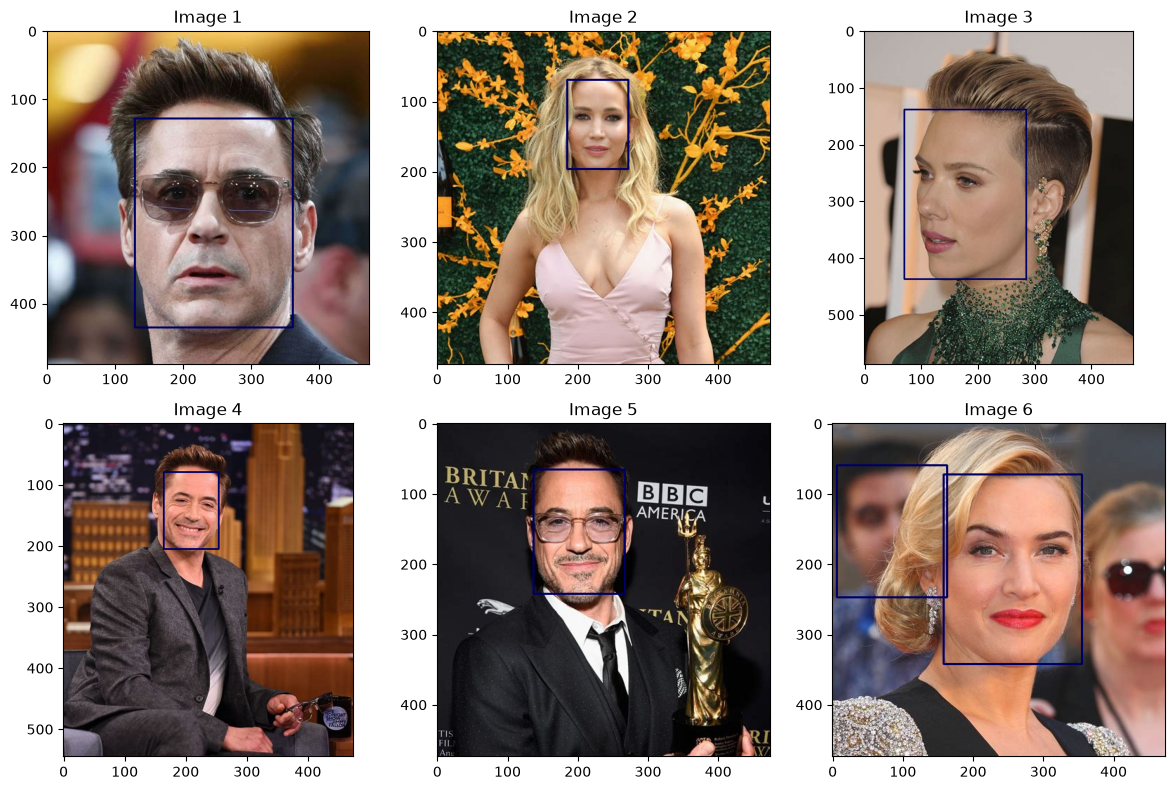

In [32]:
plt.figure(figsize=(12,8))
for i in range(6):
    plt.subplot(2,3, i+1)
    plt.imshow(sample_images[i],cmap="gray")
    plt.title("Image {}".format(i+1))
    plt.grid(False)
plt.tight_layout()

In [33]:
mtcnn_detector([image1,image2])

100%|██████████| 2/2 [00:00<00:00,  7.53it/s]


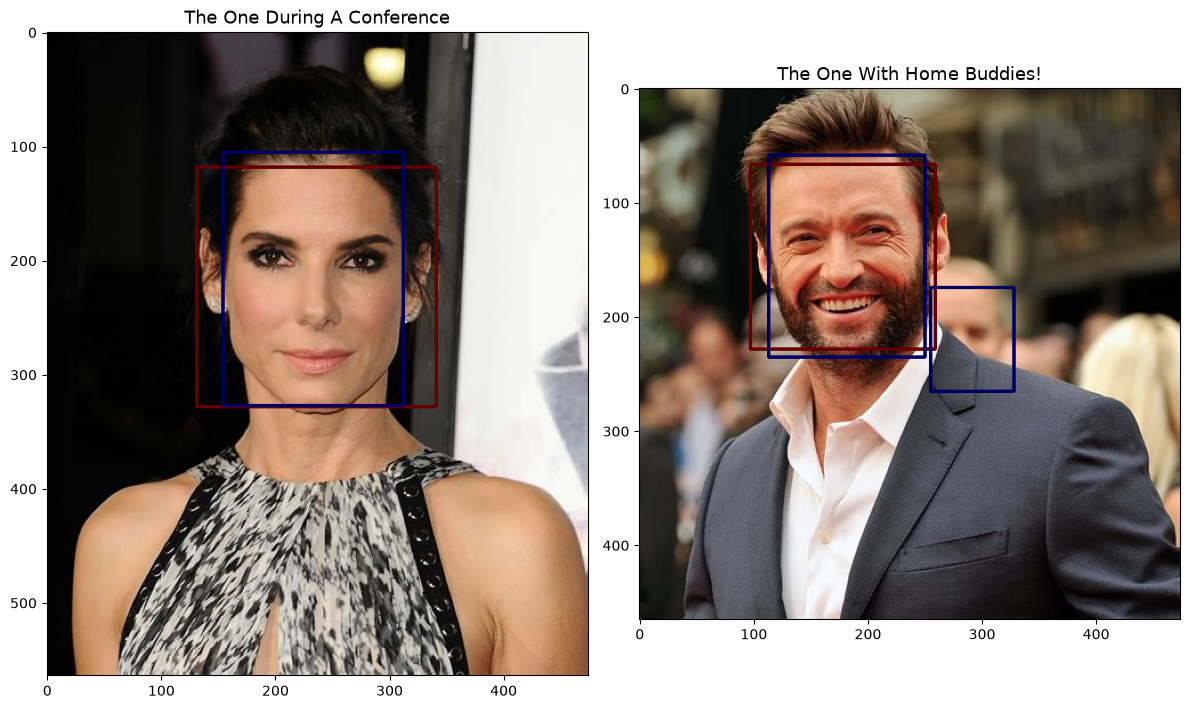

In [34]:
plt.figure(figsize = (12, 8))
plt.subplot(1,2,1) 
plt.title("The One During A Conference", fontsize = 13)
plt.imshow(image1, cmap = "gray")
plt.grid(False)

plt.subplot(1,2,2) 
plt.title("The One With Home Buddies!", fontsize = 13)
plt.imshow(image2, cmap = "gray")
plt.grid(False)

plt.tight_layout()